# 01 – Download Z4–Z6 (Team member 2)

Downloads FRED series for **Z4 industrial production**, **Z5 core inflation** and **Z6 monetary policy**, converts everything to **monthly month-end values**, builds the three explanatory variables, and saves them.

| Variable | FRED series | Frequency | Month-end rule | Feature |
|---|---|---|---|---|
| Z4 | `INDPRO` (Industrial Production Index, SA) | monthly | the monthly value | month-over-month % growth |
| Z5 | `CPILFESL` (CPI less food & energy, SA) | monthly | the monthly value | year-over-year % inflation |
| Z6 | `DFF` (effective federal funds rate) | **daily** | **last observation of the month** | month-end level (%) |

`FEDFUNDS` (monthly average) is downloaded only as a cross-check of the daily series.

Date convention: each month is labelled by its **first day** (`freq="MS"`), exactly like the Z1–Z3 files, so the files can be merged on `date`. The *value* in that row is the month-end observation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
print("pandas version:", pd.__version__)

pandas version: 3.0.5


In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
if not (ROOT / "requirements.txt").exists():
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")

RAW_DIR = ROOT / "data" / "raw" / "fred"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
for folder in (RAW_DIR, INTERIM_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: C:\Users\khupa\OneDrive - Indiana University\Documents\Financial Econometrics\project\Econ524FinalProject


## Dates and series codes

In [3]:
RAW_START = "1994-01-01"      # 24-month buffer before the sample: 12 months for Z5's YoY, 1 for Z4's growth
SAMPLE_START = "1996-01-01"   # all three series exist well before 1996
SAMPLE_END = "2026-10-31"     # Last complete calendar month as of 2026-11-27

SERIES_CODES = ["INDPRO", "CPILFESL", "DFF", "FEDFUNDS"]
print("Downloading:", ", ".join(SERIES_CODES))

Downloading: INDPRO, CPILFESL, DFF, FEDFUNDS


## Download each FRED series

In [4]:
def download_fred_csv(series_code, start, end):
    url = (
        "https://fred.stlouisfed.org/graph/fredgraph.csv"
        f"?id={series_code}&cosd={start}&coed={end}"
    )
    observations = pd.read_csv(url, na_values=["."])
    date_col = "observation_date" if "observation_date" in observations.columns else "DATE"
    if date_col not in observations.columns or series_code not in observations.columns:
        raise ValueError(f"Unexpected FRED CSV format for {series_code}: {observations.columns.tolist()}")
    observations[date_col] = pd.to_datetime(observations[date_col])
    observations[series_code] = pd.to_numeric(observations[series_code], errors="coerce")
    observations = observations.set_index(date_col).sort_index()
    observations.index.name = "date"
    return observations.loc[start:end, [series_code]]

raw = {}
for series_code in SERIES_CODES:
    try:
        observations = download_fred_csv(series_code, RAW_START, SAMPLE_END)
    except Exception as exc:
        raise RuntimeError(f"Could not download {series_code} from FRED") from exc

    if observations.empty:
        raise ValueError(f"FRED returned no observations for {series_code}")

    first_obs = observations[series_code].first_valid_index()
    if first_obs > pd.Timestamp(RAW_START) + pd.Timedelta(days=45):
        raise ValueError(f"{series_code} starts only on {first_obs:%Y-%m-%d}; "
                         f"it does not cover the requested start {RAW_START}.")

    observations.to_csv(RAW_DIR / f"{series_code}.csv", date_format="%Y-%m-%d")
    raw[series_code] = observations[series_code]

    print(f"{series_code}: {len(observations):,} records; "
          f"{observations.index.min():%Y-%m-%d} to "
          f"{observations.index.max():%Y-%m-%d}")

INDPRO: 394 records; 1994-01-01 to 2026-10-01
CPILFESL: 394 records; 1994-01-01 to 2026-10-01


DFF: 11,992 records; 1994-01-01 to 2026-10-31
FEDFUNDS: 394 records; 1994-01-01 to 2026-10-01


Raw observations

In [5]:
display(raw["DFF"].tail())
display(raw["INDPRO"].head())
display(raw["CPILFESL"].head())

date
2026-10-27    3.88
2026-10-28    3.88
2026-10-29    3.88
2026-10-30    3.88
2026-10-31    3.88
Name: DFF, dtype: float64

date
1994-01-01    65.9778
1994-02-01    66.0179
1994-03-01    66.7005
1994-04-01    67.0891
1994-05-01    67.3990
Name: INDPRO, dtype: float64

date
1994-01-01    154.5
1994-02-01    154.8
1994-03-01    155.3
1994-04-01    155.5
1994-05-01    155.9
Name: CPILFESL, dtype: float64

## Convert everything to monthly month-end observations

`resample("ME").last()` keeps the **last available observation in each calendar month**. For `INDPRO` and `CPILFESL` (already monthly) that is simply the monthly value; for the daily `DFF` it is the rate on the last day of the month (FRED's daily rate includes weekends, so this is the calendar month-end). The result is then re-labelled to the first day of the month to match the Z1–Z3 files.

In [6]:
def to_month_end(series):
    month_end = series.dropna().resample("ME").last()
    month_end.index = month_end.index.to_period("M").to_timestamp()   # label = first day of month
    month_end.index.name = "date"
    return month_end

full_months = pd.date_range(RAW_START, SAMPLE_END, freq="MS", name="date")
levels_full = pd.concat({code: to_month_end(series) for code, series in raw.items()}, axis=1)
levels_full = levels_full.reindex(full_months)

months = pd.date_range(SAMPLE_START, SAMPLE_END, freq="MS", name="date")
levels = levels_full.reindex(months)

display(levels.head())
display(levels.tail())
print("Monthly rows in sample:", len(levels))

,INDPRO,CPILFESL,DFF,FEDFUNDS
date,,,,
1996-01-01,71.7570,163.7,5.71,5.56
1996-02-01,72.8034,164.0,6.05,5.22
1996-03-01,72.7290,164.4,5.25,5.31
1996-04-01,73.4613,164.6,5.50,5.22
1996-05-01,74.0210,165.0,5.31,5.24


,INDPRO,CPILFESL,DFF,FEDFUNDS
date,,,,
2026-06-01,101.9827,336.065,3.63,3.63
2026-07-01,102.2082,336.789,3.63,3.63
2026-08-01,102.0644,337.765,3.63,3.63
2026-09-01,102.6785,338.896,3.88,3.75
2026-10-01,102.2421,339.900,3.88,3.88


Monthly rows in sample: 370


Which daily observation was used for each month? (DFF should be the last calendar day)

In [7]:
dff_obs = raw["DFF"].dropna()
used_dates = dff_obs.index.to_series().resample("ME").last()
display(used_dates.tail(6).to_frame("dff_observation_date_used"))
assert (used_dates.index == used_dates.values).all() or (
    (used_dates.index - used_dates.values).days.max() <= 3
), "DFF month-end observation is more than 3 days before month-end."
print("OK: DFF month-end observations fall on (or within 3 days of) the calendar month-end.")

,dff_observation_date_used
date,
2026-05-31,2026-05-31
2026-06-30,2026-06-30
2026-07-31,2026-07-31
2026-08-31,2026-08-31
2026-09-30,2026-09-30
2026-10-31,2026-10-31


OK: DFF month-end observations fall on (or within 3 days of) the calendar month-end.


Cross-check: month-end DFF vs FRED's monthly-average `FEDFUNDS`

,DFF_month_end,FEDFUNDS_monthly_avg,difference
count,370.000,370.000,370.000
mean,2.517,2.476,0.041
std,2.248,2.175,0.250
min,0.040,0.050,-1.310
25%,0.160,0.162,-0.020
50%,1.910,1.820,0.000
75%,4.838,4.807,0.070
max,7.070,6.540,1.680


Share of months where |month-end - monthly average| > 0.25 pp: 0.132


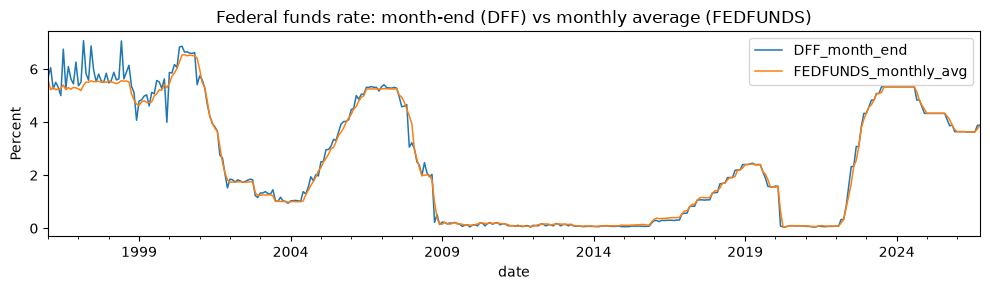

In [8]:
check = pd.DataFrame({
    "DFF_month_end": levels["DFF"],
    "FEDFUNDS_monthly_avg": levels_full["FEDFUNDS"].reindex(months),
})
# FEDFUNDS above is itself passed through the month-end rule, which is a no-op for a monthly series
check["difference"] = check["DFF_month_end"] - check["FEDFUNDS_monthly_avg"]
display(check.describe().round(3))
print("Share of months where |month-end - monthly average| > 0.25 pp:",
      round((check["difference"].abs() > 0.25).mean(), 3))

fig, ax = plt.subplots(figsize=(10, 3))
check[["DFF_month_end", "FEDFUNDS_monthly_avg"]].plot(ax=ax, linewidth=1.1)
ax.set_title("Federal funds rate: month-end (DFF) vs monthly average (FEDFUNDS)")
ax.set_ylabel("Percent")
plt.tight_layout()
plt.show()

## Calculate your three explanatory variables

Features are computed on the buffered series (`levels_full`) so the first sample month (1996-01) is not lost to differencing, then cut back to the sample.

In [9]:
ip = levels_full["INDPRO"]
core = levels_full["CPILFESL"]
ff = levels_full["DFF"]

features = pd.DataFrame(index=months)
features["z4_ip_growth"] = (ip.pct_change() * 100).reindex(months)            # MoM %, industrial production
features["z5_core_inflation"] = (core.pct_change(12) * 100).reindex(months)   # YoY %, core CPI
features["z6_fed_funds"] = ff.reindex(months)                                  # month-end level, %
features.index.name = "date"

# Alternative transformations (used in the EDA notebook to compare stationarity)
alternatives = pd.DataFrame(index=months)
alternatives["z4_ip_yoy"] = (ip.pct_change(12) * 100).reindex(months)
alternatives["z5_core_inflation_mom"] = (core.pct_change() * 100).reindex(months)
alternatives["z6_fed_funds_change"] = ff.diff().reindex(months)
alternatives.index.name = "date"

display(features.head(12))
display(features.tail(6))

,z4_ip_growth,z5_core_inflation,z6_fed_funds
date,,,
1996-01-01,-0.590855,2.955975,5.71
1996-02-01,1.458255,2.885822,6.05
1996-03-01,-0.102193,2.814259,5.25
1996-04-01,1.006889,2.618454,5.50
1996-05-01,0.761898,2.675793,5.31
1996-06-01,0.744789,2.669150,5.00
1996-07-01,0.003487,2.664188,6.75
1996-08-01,0.506739,2.595797,5.28
1996-09-01,0.626928,2.651048,6.09


,z4_ip_growth,z5_core_inflation,z6_fed_funds
date,,,
2026-05-01,0.136561,2.822942,3.62
2026-06-01,0.201026,2.565785,3.63
2026-07-01,0.221116,2.466518,3.63
2026-08-01,-0.140693,2.446163,3.63
2026-09-01,0.601679,2.565841,3.88
2026-10-01,-0.425016,NaN,3.88


Check for missing values

In [10]:
all_cols = pd.concat([levels, features, alternatives], axis=1)
quality = pd.DataFrame({
    "available_months": all_cols.notna().sum(),
    "missing_months": all_cols.isna().sum(),
    "first_available": [all_cols[c].first_valid_index() for c in all_cols],
    "last_available": [all_cols[c].last_valid_index() for c in all_cols],
})
display(quality)

if all_cols.isna().any().any():
    print("Some months are missing. Check FRED release coverage before modeling.")
else:
    print("No missing months in the sample.")

,available_months,missing_months,first_available,last_available
INDPRO,370,0,1996-01-01,2026-10-01
CPILFESL,369,1,1996-01-01,2026-10-01
DFF,370,0,1996-01-01,2026-10-01
FEDFUNDS,370,0,1996-01-01,2026-10-01
z4_ip_growth,370,0,1996-01-01,2026-10-01
z5_core_inflation,368,2,1996-01-01,2026-09-01
z6_fed_funds,370,0,1996-01-01,2026-10-01
z4_ip_yoy,370,0,1996-01-01,2026-10-01
z5_core_inflation_mom,368,2,1996-01-01,2026-10-01
z6_fed_funds_change,370,0,1996-01-01,2026-10-01


Some months are missing. Check FRED release coverage before modeling.


Quick visual sanity check

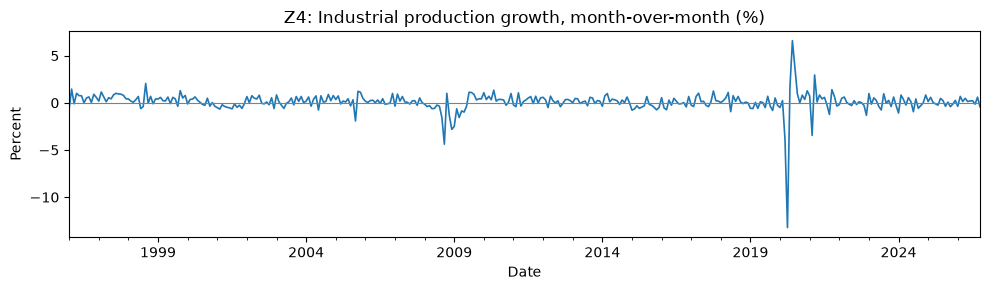

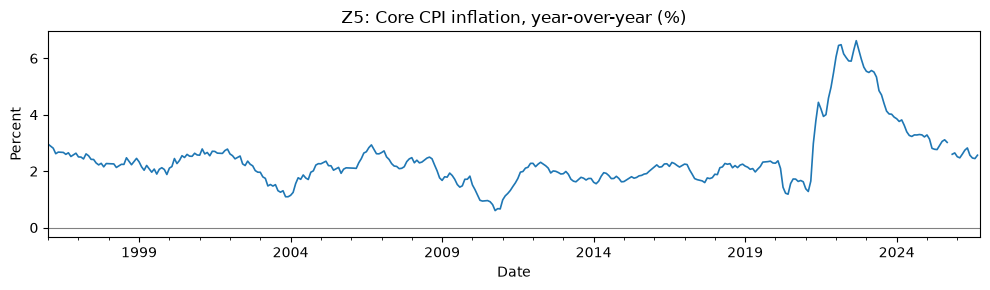

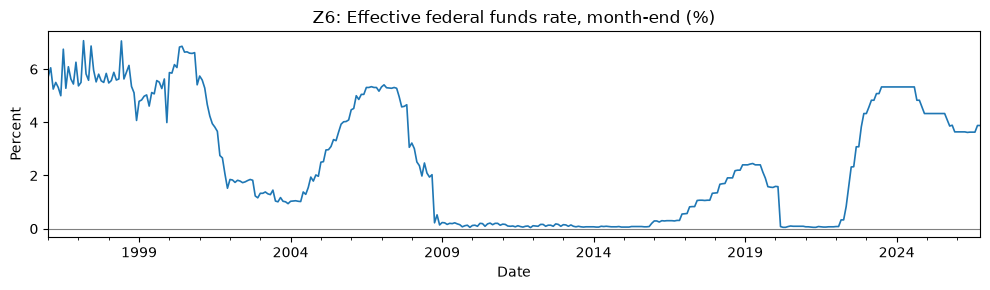

In [11]:
names = {
    "z4_ip_growth": "Z4: Industrial production growth, month-over-month (%)",
    "z5_core_inflation": "Z5: Core CPI inflation, year-over-year (%)",
    "z6_fed_funds": "Z6: Effective federal funds rate, month-end (%)",
}
for column, title in names.items():
    fig, ax = plt.subplots(figsize=(10, 3))
    features[column].plot(ax=ax, linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Percent")
    ax.axhline(0, color="gray", linewidth=0.8)
    plt.tight_layout()
    plt.show()

In [12]:
levels_path = INTERIM_DIR / "z4_z6_levels_monthly.csv"
features_path = PROCESSED_DIR / "z4_z6_monthly.csv"
alternatives_path = PROCESSED_DIR / "z4_z6_alternatives_monthly.csv"

levels.to_csv(levels_path, date_format="%Y-%m-%d")
features.to_csv(features_path, date_format="%Y-%m-%d")
alternatives.to_csv(alternatives_path, date_format="%Y-%m-%d")

print("Saved:", levels_path.relative_to(ROOT))
print("Saved:", features_path.relative_to(ROOT))
print("Saved:", alternatives_path.relative_to(ROOT))
print("Next: run notebooks/02_eda_stationarity_z4_z6.ipynb")

Saved: data\interim\z4_z6_levels_monthly.csv
Saved: data\processed\z4_z6_monthly.csv
Saved: data\processed\z4_z6_alternatives_monthly.csv
Next: run notebooks/02_eda_stationarity_z4_z6.ipynb
